# 08 — SHAP Explainability

Explain global feature contributions. Interpret them as model associations, not causal effects.

In [3]:
%pip install shap joblib

  Using cached slicer-0.0.8-py3-none-any.whl.metadata (4.0 kB)
   ---------------------------------------- 0.0/755.4 kB ? eta -:--:--
   --------------------------- ------------ 524.3/755.4 kB 8.0 MB/s eta 0:00:01
   ---------------------------------------- 755.4/755.4 kB 6.1 MB/s eta 0:00:00
Using cached slicer-0.0.8-py3-none-any.whl (15 kB)

   ---------------------------------------- 0/2 [slicer]
   ---------------------------------------- 0/2 [slicer]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1

In [7]:
from pathlib import Path
import sys, pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
ROOT = Path.cwd().resolve()
if not (ROOT/"src").exists(): ROOT = ROOT.parent
sys.path.append(str(ROOT))
DATA = ROOT/"data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv"
assert DATA.exists(), f"Download the dataset and place it at {DATA}"


In [8]:
import joblib, shap
from src.data_cleaning import clean_data, prepare_target
from src.feature_engineering import add_business_features


Background dataset has 500 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=500 when initializing the masker.


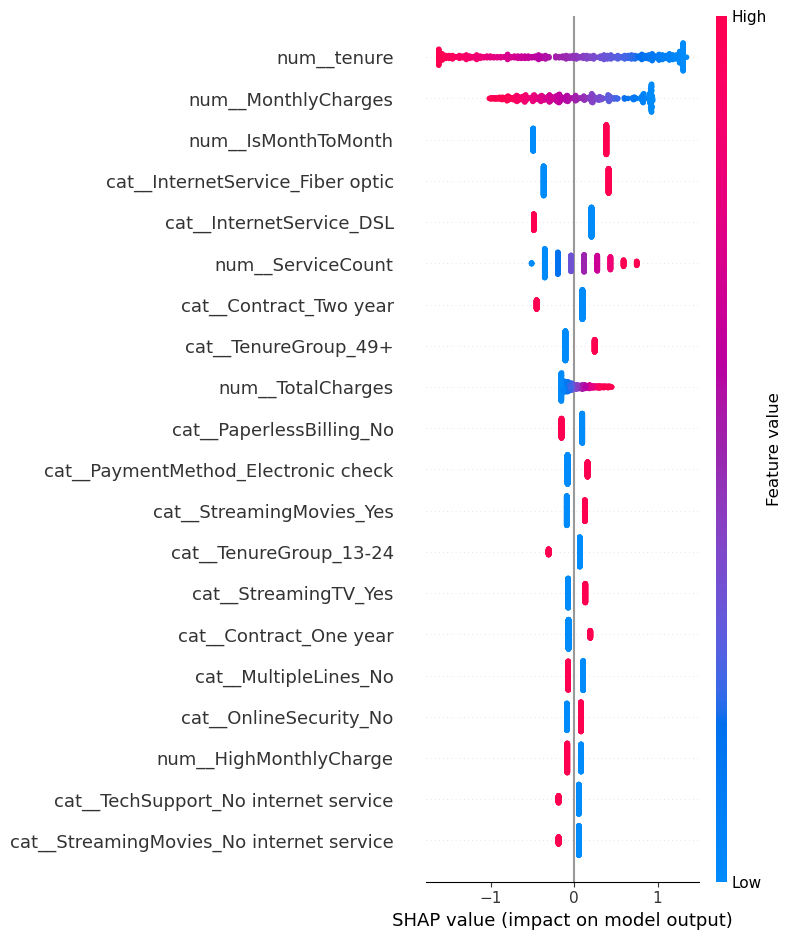

In [9]:

df=add_business_features(prepare_target(clean_data(pd.read_csv(DATA))))
model=joblib.load(ROOT/'models/final_model1.joblib'); X=df.drop(columns=['Churn','customerID'])
pre=model.named_steps['preprocessor']; est=model.named_steps['model']; Xt=pre.transform(X); names=pre.get_feature_names_out(); sample=Xt[:min(500,Xt.shape[0])]
try:
    if est.__class__.__name__ in {'RandomForestClassifier','XGBClassifier'}:
        ex=shap.TreeExplainer(est); sv=ex.shap_values(sample); sv=sv[1] if isinstance(sv,list) else sv
    else:
        ex=shap.LinearExplainer(est,sample); sv=ex.shap_values(sample)
    shap.summary_plot(sv,sample,feature_names=names,show=False); plt.tight_layout(); plt.savefig(ROOT/'images/shap/shap_summary.png',dpi=160,bbox_inches='tight'); plt.show()
except Exception as e: print('Check SHAP compatibility with selected estimator:',e)

Use the final SHAP plot to write actual driver observations in `reports/business_insights.md`.